# Inklight + Docling structure on Indra's OCR — a live showcase

Everything below is computed when the notebook runs, on this machine, with the real components:

* **Indra** reads the text (the only OCR).
* **Docling** finds layout, reading order and tables (Heron layout model, TableFormer) **on Indra's lines** — no second OCR.
* **Inklight** indexes, answers and cites.

The documents are **synthetic**: fictional registration cards (Arabic, English, mixed) written by
`bench/structure/make_synthetic.py`, saved as scans so Indra must OCR them. No private data.

Sections: 1 setup · 2 Indra OCR · 3 Docling on Indra's lines (and proof there is no second OCR) · 4 the tables ·
5 answers before/after · 6 honesty about OCR errors · 7 speed · 8 exports.

In [1]:
import os, sys, time, json, platform, subprocess, tempfile, warnings, contextlib, io
os.environ["TQDM_DISABLE"] = "1"                 # no download/loading progress bars in the output
warnings.filterwarnings("ignore")
from pathlib import Path
from importlib.metadata import version

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "examples" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "bench" / "structure"))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pymupdf

pd.set_option("display.max_colwidth", 90)
OUT = ROOT / "examples" / "showcase_out"
OUT.mkdir(parents=True, exist_ok=True)
# The Indra models used for the measurements in docs/STRUCTURE.md, when present; otherwise Indra's default download.
PILOT = Path(r"C:/Users/pc/inklight-pilot-b4/models/indra")
INDRA_MODELS = str(PILOT) if PILOT.exists() else None

commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
pd.Series({
    "inklight commit": commit,
    "python": platform.python_version(),
    "indra-ocr": version("indra-ocr"),
    "docling": version("docling"),
    "docling-core": version("docling-core"),
    "torch": version("torch"),
    "cpu cores": os.cpu_count(),
}, name="environment").to_frame()

,environment
inklight commit,7210ea4
python,3.13.9
indra-ocr,1.1.2
docling,2.142.1
docling-core,2.104.0
torch,2.12.1
cpu cores,16


## 1 · The documents
The generator writes each card twice: with a text layer, and as a scan (images only).

['regcard-ar-scan.pdf', 'regcard-ar.pdf', 'regcard-en-scan.pdf', 'regcard-en.pdf', 'regcard-mixed-scan.pdf', 'regcard-mixed.pdf']


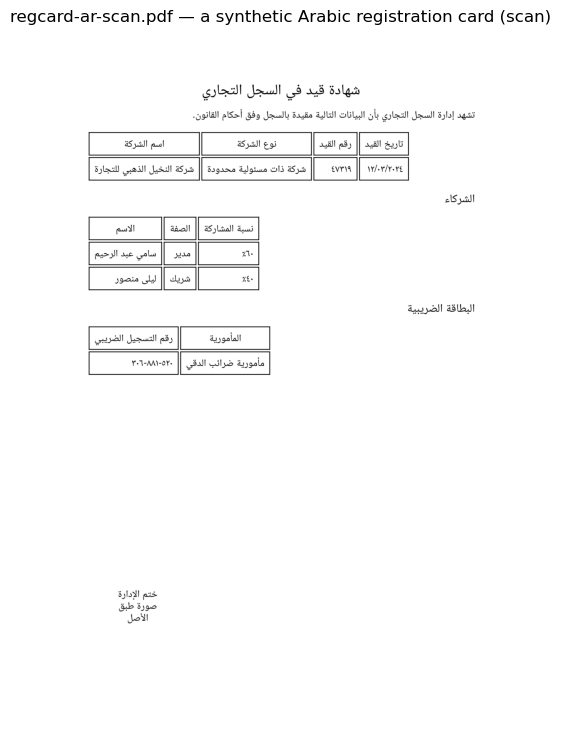

In [2]:
import make_synthetic
sys.argv = ["make_synthetic", str(OUT)]
with contextlib.redirect_stdout(io.StringIO()):
    make_synthetic.main()
print(sorted(p.name for p in OUT.glob("regcard-*.pdf")))

def show_page(pdf, title, boxes=(), scale=200 / 72, figsize=(9, 11), color="red"):
    """The page rendered in Inklight's pixel frame (Indra's 200 dpi), with boxes drawn on it."""
    page = pymupdf.open(pdf)[0]
    pix = page.get_pixmap(matrix=pymupdf.Matrix(scale, scale))
    import numpy as np
    arr = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(arr)
    for box in boxes:
        x0, y0, x1, y1 = box[:4]
        c = box[4] if len(box) > 4 else color
        ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=c, linewidth=1.6))
    ax.set_title(title); ax.axis("off"); plt.show()

show_page(OUT / "regcard-ar-scan.pdf", "regcard-ar-scan.pdf — a synthetic Arabic registration card (scan)", figsize=(7, 9))

## 2 · Indra reads the page
Indra's lines are what Inklight stores — text, box, confidence — and they are never changed afterwards.

In [3]:
from inklight.config import OCRSettings, StructureSettings
from inklight.ocr.indra import IndraEngine

indra = IndraEngine(OCRSettings(model_dir=INDRA_MODELS))
indra.read(OUT / "regcard-en-scan.pdf", max_pages=1)          # warm-up: Indra loads its models once
t = time.perf_counter()
content = indra.read(OUT / "regcard-ar-scan.pdf", max_pages=5)
print(f"Indra OCR: {time.perf_counter() - t:.2f} s for {len(content.pages)} page(s), {len(content.pages[0].lines)} lines")
page = content.pages[0]
pd.DataFrame([{"text": l.text, "confidence": l.conf, "box (pixels)": l.bbox} for l in page.lines])

Indra OCR: 0.24 s for 1 page(s), 28 lines


,text,confidence,box (pixels)
0,شهادة قيد في السجل التجاري,0.9787,"(553.3, 179.6, 1100.5, 237.1)"
1,تشهد إدارة السجل التجاري بأن البيانات التالية مقيدة بالسجل وفق أحكام القانون.,0.9633,"(528.0, 264.8, 1486.6, 308.0)"
2,تاريخ القيد رقم القيد,0.8849,"(946.5, 360.3, 1250.8, 415.3)"
3,نوع الشركة,0.9388,"(675.2, 368.7, 814.1, 405.1)"
4,اسم الشركة,0.9634,"(296.6, 370.4, 434.4, 403.4)"
5,14/-V/V-46,0.7461,"(1109.8, 450.7, 1238.4, 483.4)"
6,evra,0.5621,"(986.4, 451.7, 1110.4, 484.4)"
7,شركة ذات مسئولية محدودة,0.9317,"(572.0, 453.3, 915.1, 491.5)"
8,شركة النخيل الذهبي للتجارة,0.9317,"(195.3, 453.3, 536.8, 491.5)"
9,الشركاء,0.9977,"(1378.5, 552.3, 1485.9, 590.5)"


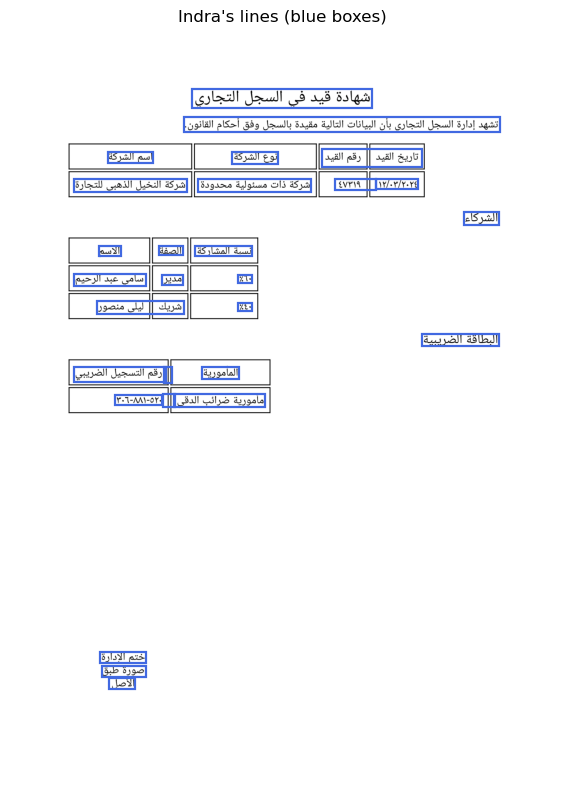

In [4]:
show_page(OUT / "regcard-ar-scan.pdf", "Indra's lines (blue boxes)", [(*l.bbox, "royalblue") for l in page.lines], figsize=(8, 10))

## 3 · Docling on Indra's lines

Inklight registers an OCR engine with Docling that does **no recognition**: it hands Docling Indra's stored lines as
its text cells (`OcrMode.FULL_PAGE`). Docling's own layout model, reading order and TableFormer then run unchanged.
Each run records what it did.

In [6]:
from inklight.structure import structure_document, load_document

settings = StructureSettings(engine="docling")      # the defaults: accurate tables, ONNX layout, every core
t = time.perf_counter()
done = structure_document(OUT / "regcard-ar-scan.pdf", content, settings)
first = time.perf_counter() - t
t = time.perf_counter()
done = structure_document(OUT / "regcard-ar-scan.pdf", content, settings)
again = time.perf_counter() - t
m = done.meta
print(f"first run (loads the models): {first:.1f} s   ·   next run (models loaded): {again:.2f} s")
pd.Series({
    "Indra lines with text and box": sum(1 for l in page.lines if l.text.strip() and l.bbox),
    "cells handed to Docling": m["cells_delivered"],
    "words in Docling's output Indra never read": m["foreign_tokens"],
    "Indra lines no Docling item holds": m["orphan_lines"],
    "tables found": m["tables"],
    "layout": m["components"]["layout"],
    "tables model": m["components"]["tables"],
    "OCR inside Docling": m["components"]["ocr"],
}, name="this run").to_frame()

first run (loads the models): 1.8 s   ·   next run (models loaded): 1.90 s


,this run
Indra lines with text and box,26
cells handed to Docling,26
words in Docling's output Indra never read,0
Indra lines no Docling item holds,0
tables found,1
layout,Heron (onnx)
tables model,"TableFormer (accurate), cell matching on the given text cells"
OCR inside Docling,none in Docling: Indra's stored lines are its text cells (OcrMode.FULL_PAGE)


### Proof there is no second OCR

Control experiment: replace **every** Indra line with a marker word (`MARK0`, `MARK1`, …) and run Docling again on the
same page image. If Docling read the page itself, real words would appear. Only the markers come back.

In [7]:
from inklight.schemas import TextLine
marked = content.model_copy(update={"pages": tuple(
    p.model_copy(update={"lines": tuple(TextLine(text=f"MARK{i}", bbox=l.bbox) for i, l in enumerate(p.lines))})
    for p in content.pages)})
control = structure_document(OUT / "regcard-ar-scan.pdf", marked, settings)
words = sorted({w.strip("|:") for p in control.content.pages for b in p.blocks for w in b.text.split()} - {""})
print("words in Docling's output:", words[:12], "…")
print("anything that is not a marker?", [w for w in words if not w.startswith("MARK")])

words in Docling's output: ['MARK0', 'MARK1', 'MARK10', 'MARK11', 'MARK12', 'MARK13', 'MARK14', 'MARK15', 'MARK16', 'MARK17', 'MARK18', 'MARK19'] …
anything that is not a marker? []


## 4 · What Docling recovered: blocks in reading order, and the tables cell by cell

In [8]:
blocks = done.content.pages[0].blocks
pd.DataFrame([{"label": b.label, "docling ref": b.ref, "text (tables: header: value)": b.text} for b in blocks])

,label,docling ref,text (tables: header: value)
0,Section-Header,#/texts/0,شهادة قيد في السجل التجاري
1,Text,#/texts/1,تشهد إدارة السجل التجاري بأن البيانات التالية مقيدة بالسجل وفق أحكام القانون.
2,Table,#/tables/0,الشركاء\nالبطاقة الضريبية\nاسم الشركة: شركة النخيل الذهبي للتجارة | نوع الشركة: شركة ذ...
3,Text,#/texts/2,ختم الإدارة صورة طبق الأصل


In [9]:
from inklight.structure.adapter import table_grid
document = load_document(done.document_json)
for t in document.tables:
    g = table_grid(t, document)
    df = pd.DataFrame(g.rows)
    df.index = ["header" if r in g.header_rows else f"row {r}" for r in range(len(g.rows))]
    print(t.self_ref, "— header rows flagged by TableFormer:", sorted(g.header_rows))
    display(df)

#/tables/0 — header rows flagged by TableFormer: [0]


,0,1,2,3,4
header,اسم الشركة,اسم الشركة,نوع الشركة,تاريخ القيد رقم القيد,
row 1,شركة النخيل الذهبي للتجارة,شركة النخيل الذهبي للتجارة,شركة ذات مسئولية محدودة,14/-V/V-46 evra,
row 2,,,,,الشركاء
row 3,الاسم,الصفة,نسبة المشاركة,,
row 4,سامي عبد الرحيم,مدیر,27.,,
row 5,شريكليلى منصور,,22.,,
row 6,,,,,البطاقة الضريبية
row 7,رقم التسجيل الضريبي,رقم التسجيل الضريبي,المأمورية,,
row 8,P. 7-11-08.,P. 7-11-08.,مأمورية ضرائب الدقي,,


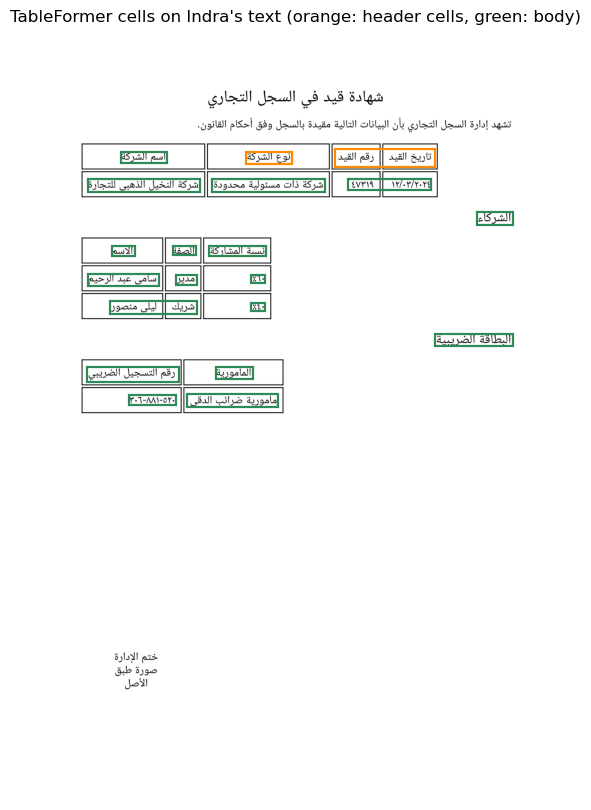

In [10]:
from inklight.structure.adapter import to_inklight
cell_boxes = []
for t in document.tables:
    size = document.pages[t.prov[0].page_no].size
    for c in t.data.table_cells:
        b = to_inklight(c.bbox, size, page)
        if b: cell_boxes.append((*b, "darkorange" if c.column_header else "seagreen"))
show_page(OUT / "regcard-ar-scan.pdf", "TableFormer cells on Indra's text (orange: header cells, green: body)", cell_boxes, figsize=(8, 10))

## 5 · Answers before and after

Two fresh libraries read the **same** scans with the **same** Indra OCR, in rules mode (no language model):

* **without structure** — Inklight as before (`[structure] engine = "none"`),
* **with structure** — Docling's tables on Indra's lines (`engine = "docling"`).

The questions name a field printed as a column heading over its value, or a person in a table of several people.

In [11]:
from inklight import DocumentAgent
from inklight.config import ModelSettings, Settings

FILES = ["regcard-ar-scan.pdf", "regcard-en-scan.pdf", "regcard-mixed-scan.pdf"]
QUESTIONS = [
    ("regcard-ar-scan.pdf", "ما اسم الشركة؟", "شركة النخيل الذهبي للتجارة"),
    ("regcard-ar-scan.pdf", "ما نوع الشركة؟", "شركة ذات مسئولية محدودة"),
    ("regcard-ar-scan.pdf", "من المدير؟", "سامي عبد الرحيم"),
    ("regcard-ar-scan.pdf", "ما المأمورية؟", "مأمورية ضرائب الدقي"),
    ("regcard-en-scan.pdf", "What is the company name?", "Golden Palm Trading Co"),
    ("regcard-en-scan.pdf", "What is the company type?", "Limited liability company"),
    ("regcard-en-scan.pdf", "What is the registration number?", "47319"),
    ("regcard-en-scan.pdf", "Who is the manager?", "Samuel Reed"),
    ("regcard-en-scan.pdf", "What is Laila Mansour's share?", "40%"),
    ("regcard-mixed-scan.pdf", "What is the registration number?", "47319"),
    ("regcard-mixed-scan.pdf", "ما رقم القيد؟", "47319"),
]

def ask_all(engine):
    home = Path(tempfile.mkdtemp(prefix=f"showcase-{engine}-"))
    s = Settings(home=home, ocr=OCRSettings(model_dir=INDRA_MODELS),
                 models=ModelSettings(brain="rules", allow_download=False), structure={"engine": engine})
    out = []
    with DocumentAgent(s) as agent:
        t = time.perf_counter(); agent.add([OUT / f for f in FILES]); ingest = time.perf_counter() - t
        ids = {d.name: d.id for d in agent.library.documents()}
        for doc, q, expect in QUESTIONS:
            r = agent.ask(q, doc_ids=[ids[doc]], save=False)
            head = r.answer.split("\n\nEvidence:")[0].strip()
            flagged = any(w.startswith("Low confidence") for w in r.warnings)
            declined = head.startswith(("I couldn't find", "I could not find"))
            right = expect.lower() in head.lower()
            listed = " values under " in head  # several rows listed, none chosen
            verdict = ("declined" if declined else "listed, not chosen" if listed
                       else ("correct" if right else "WRONG") + (" (flagged)" if flagged else ""))
            src = r.sources[0] if r.sources else None
            out.append({"question": q, "answer": head[:60], "verdict": verdict,
                        "cited": f"p.{src.page} {tuple(round(v) for v in src.bbox)}" if src and src.bbox else "—"})
    return pd.DataFrame(out), ingest, ids, s

before, t_before, _, _ = ask_all("none")
after, t_after, ids_after, s_after = ask_all("docling")
print(f"ingest of {len(FILES)} scans: without structure {t_before:.1f} s · with structure {t_after:.1f} s (includes loading Docling)")
pd.concat({"without structure": before.drop(columns=["question"]), "with structure": after.drop(columns=["question"])},
          axis=1).set_index(before["question"])

ingest of 3 scans: without structure 1.8 s · with structure 5.6 s (includes loading Docling)


without structure  \
                                                                                        answer   
question                                                                                         
ما اسم الشركة؟                    I couldn't find supporting evidence for the الشركه in the pr   
ما نوع الشركة؟                    I couldn't find supporting evidence for the نوع الشركه in th   
من المدير؟                        I couldn't find supporting evidence for the المدير in the pr   
ما المأمورية؟                     I couldn't find supporting evidence for the الماموريه in the   
What is the company name?         I couldn't find supporting evidence for the company in the p   
What is the company type?         I couldn't find supporting evidence for the company in the p   
What is the registration number?                        Certificate of Commercial Registration   
Who is the manager?                                                                        60%   
What is Laila Mansour's share?    I couldn't find supporting evidence for the share in the pro   
What is the registration number?                                                         47319   
ما رقم القيد؟                     I couldn't find supporting evidence for the القيد in the pro   

                                                                       \
                                   verdict                      cited   
question                                                                
ما اسم الشركة؟                    declined                          —   
ما نوع الشركة؟                    declined                          —   
من المدير؟                        declined                          —   
ما المأمورية؟                     declined                          —   
What is the company name?         declined                          —   
What is the company type?         declined                          —   
What is the registration number?     WRONG  p.1 (368, 180, 1281, 226)   
Who is the manager?                  WRONG   p.1 (447, 858, 694, 893)   
What is Laila Mansour's share?    declined                          —   
What is the registration number?   correct   p.1 (196, 505, 812, 537)   
ما رقم القيد؟                     declined                          —   

                                              with structure           \
                                                      answer  verdict   
question                                                                
ما اسم الشركة؟                    شركة النخيل الذهبي للتجارة  correct   
ما نوع الشركة؟                       شركة ذات مسئولية محدودة  correct   
من المدير؟                                   سامي عبد الرحيم  correct   
ما المأمورية؟                            مأمورية ضرائب الدقي  correct   
What is the company name?            Golden Palm Trading Co.  correct   
What is the company type?          Limited liability company  correct   
What is the registration number?                       47319  correct   
Who is the manager?                              Samuel Reed  correct   
What is Laila Mansour's share?                           40%  correct   
What is the registration number?                       47319  correct   
ما رقم القيد؟                                          47319  correct   

                                                              
                                                       cited  
question                                                      
ما اسم الشركة؟                      p.1 (195, 453, 537, 492)  
ما نوع الشركة؟                      p.1 (572, 453, 915, 492)  
من المدير؟                          p.1 (195, 739, 412, 779)  
ما المأمورية؟                     p.1 (497, 1105, 773, 1145)  
What is the company name?           p.1 (196, 534, 392, 605)  
What is the company type?           p.1 (544, 535, 763, 605)  
What is the registration number?    p.1 (878, 535, 977, 560)  
Who is the manager?         

In [11]:
summary = pd.DataFrame({
    "without structure": before["verdict"].str.replace(r" \(flagged\)", "", regex=True).value_counts(),
    "with structure": after["verdict"].str.replace(r" \(flagged\)", "", regex=True).value_counts(),
}).fillna(0).astype(int)
summary

,without structure,with structure
verdict,,
WRONG,3,0
correct,1,11
declined,7,0


شركة النخيل الذهبي للتجارة

Evidence: “اسم الشركة: شركة النخيل الذهبي للتجارة” (table, page 1)


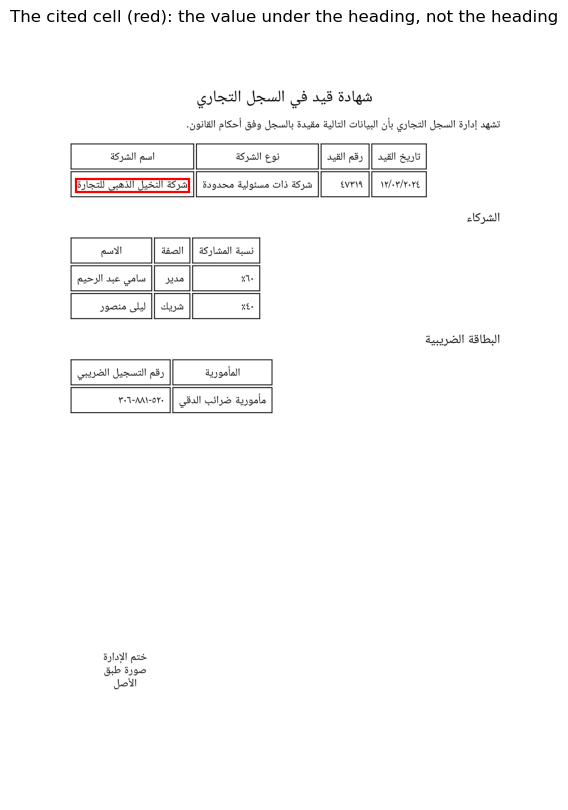

In [12]:
# Where the answer to "ما اسم الشركة؟" came from: the cited cell, in the page's pixel frame
with DocumentAgent(s_after) as agent:
    r = agent.ask("ما اسم الشركة؟", doc_ids=[ids_after["regcard-ar-scan.pdf"]], save=False)
print(r.answer)
show_page(OUT / "regcard-ar-scan.pdf", "The cited cell (red): the value under the heading, not the heading",
          [(*r.sources[0].bbox, "red")], figsize=(8, 10))

## 6 · Honest about OCR errors

Indra misreads some Arabic-Indic digits on these scans. Structure cannot fix a misread value — but the answer says
it is unsure, because Indra read that cell with low confidence.

In [13]:
with DocumentAgent(s_after) as agent:
    for q in ["ما رقم القيد؟", "ما تاريخ القيد؟"]:
        r = agent.ask(q, doc_ids=[ids_after["regcard-ar-scan.pdf"]], save=False)
        print(q, "→", r.answer.split("\n\n")[0][:70], "| confidence", r.confidence)
        for w in r.warnings: print("   ⚠", w)
        print()
print("Printed on the card: رقم القيد ٤٧٣١٩ · تاريخ القيد ١٢/٠٣/٢٠٢٤")

ما رقم القيد؟ → I couldn't find supporting evidence for a value of “تاريخ القيد رقم ال | confidence 0.4

ما تاريخ القيد؟ → I couldn't find supporting evidence for a value of “تاريخ القيد رقم ال | confidence 0.4

Printed on the card: رقم القيد ٤٧٣١٩ · تاريخ القيد ١٢/٠٣/٢٠٢٤


## 7 · Speed: where the time goes, and what the options cost

Docling's own per-stage profiler, on a 9-page scan (the synthetic cards repeated, 21 tables), with Indra's OCR
stored and replayed. Each configuration builds its own converter; the second conversion (models warm) is timed.

In [16]:
from docling.datamodel.settings import settings as docling_settings
from inklight.structure import docling_run, indra_ocr

src = pymupdf.open()
for _ in range(3):
    for f in ["regcard-ar-scan.pdf", "regcard-en-scan.pdf", "regcard-mixed-scan.pdf"]:
        src.insert_pdf(pymupdf.open(OUT / f))
nine = OUT / "nine-pages-scan.pdf"; src.save(nine)
t = time.perf_counter(); nine_content = indra.read(nine, max_pages=20); ocr_s = time.perf_counter() - t
print(f"Indra OCR of the 9 pages: {ocr_s:.1f} s")

docling_settings.debug.profile_pipeline_timings = True
def profile(**kw):
    st = StructureSettings(engine="docling", **kw)
    conv, _ = docling_run._converter(st)
    for attempt in range(2):
        with tempfile.TemporaryDirectory() as work:
            pdf = docling_run._images_only(nine, [p.number for p in nine_content.pages], Path(work), None)
            t = time.perf_counter()
            with indra_ocr.lines_for(pdf, list(nine_content.pages)):
                res = conv.convert(pdf)
            took = time.perf_counter() - t
    stages = {k: sum(v.times) for k, v in res.timings.items()}
    return {"total (s)": round(took, 2), "layout stage (s)": round(stages["layout"], 2),
            "table stage (s)": round(stages["table_structure"], 2), "tables": len(res.document.tables)}

configs = {
    "before: torch layout, 4 threads": dict(layout_runtime="torch", threads=4),
    "now (default): ONNX layout, all cores": dict(),
    "option: + fast tables": dict(table_mode="fast"),
    "option: + TableFormer v2": dict(table_model="tableformer_v2"),
}
speed = pd.DataFrame({name: profile(**kw) for name, kw in configs.items()}).T
speed

Indra OCR of the 9 pages: 2.1 s


,total (s),layout stage (s),table stage (s),tables
"before: torch layout, 4 threads",15.09,5.44,13.27,15.0
"now (default): ONNX layout, all cores",11.59,3.03,11.21,15.0
option: + fast tables,6.29,2.37,5.93,15.0
option: + TableFormer v2,7.39,2.33,7.03,15.0


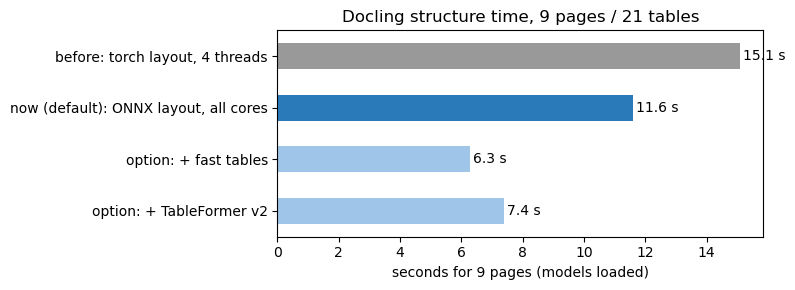

The 'fast' and 'v2' options are off by default: in the comparison (docs/STRUCTURE.md) fast tables lost one Arabic
answer and TableFormer v2 lost two low-confidence warnings. TableFormer is most of what is left.


In [17]:
ax = speed["total (s)"].plot.barh(figsize=(8, 3), color=["#999999", "#2a7ab9", "#9fc5e8", "#9fc5e8"])
ax.invert_yaxis(); ax.set_xlabel("seconds for 9 pages (models loaded)")
ax.set_title("Docling structure time, 9 pages / 21 tables")
for i, v in enumerate(speed["total (s)"]): ax.text(v + 0.1, i, f"{v:.1f} s", va="center")
plt.tight_layout(); plt.show()
print("The 'fast' and 'v2' options are off by default: in the comparison (docs/STRUCTURE.md) fast tables lost one Arabic")
print("answer and TableFormer v2 lost two low-confidence warnings. TableFormer is most of what is left.")

## 8 · Exports — Docling's own exporters on the stored structure

In [18]:
with DocumentAgent(s_after) as agent:
    meta, doc = agent.library.structure(ids_after["regcard-en-scan.pdf"])
markdown = doc.export_to_markdown(traverse_pictures=True)
print(markdown[:1200])
print("…\nJSON export:", len(json.dumps(doc.export_to_dict())), "characters ·",
      "CLI: inklight structure regcard-en-scan.pdf --format md|json|html|meta")

## Certificate of Commercial Registration

The Commercial Registry certifies that the following particulars are entered in the register.

| Company name            | Company type              |   Registration number | Registration date   |
|-------------------------|---------------------------|-----------------------|---------------------|
| Golden Palm Trading Co. | Limited liability company |                 47319 | 12/03/2024          |

## Partners

| Name          | Role    | Share   |
|---------------|---------|---------|
| Samuel Reed   | Manager | 60%     |
| Laila Mansour | Partner | 40%     |

## Tax card

| Tax registration number   | Tax office       |
|---------------------------|------------------|
| 520-881-306               | Dokki Tax Office |

Registry stamp Certified true
…
JSON export: 20148 characters · CLI: inklight structure regcard-en-scan.pdf --format md|json|html|meta


## Summary

* Indra is the only OCR. Docling's layout, reading order and TableFormer run on Indra's stored lines: every line is
  handed over, no foreign words come back, and the marker control shows no second OCR.
* Answers to "what is the X" now come from the cell under the heading — never the heading — and from the row of the
  person asked about; each answer cites the cell's page and box.
* OCR misreads are not hidden: answers built on low-confidence cells are flagged.
* Speed: the defaults (ONNX layout, all cores, models loaded during OCR) keep every answer; the faster options
  cost answers and stay off. Details and the full comparison: `docs/STRUCTURE.md`.